## Testing using the provided API

In [24]:
# Check connectivity

import requests
import numpy as np
import scipy
from pathlib import Path
from PIL import Image
from IPython.display import display
from io import BytesIO
import os 

API = "https://api.global-wheat.com"

response = requests.get(f"{API}/health", timeout=20)

response.raise_for_status()

print("Response:", response.json())

Response: {'status': 'ok', 'version': '0.1.0'}


Image 1024 x 1024 278,044 bytes


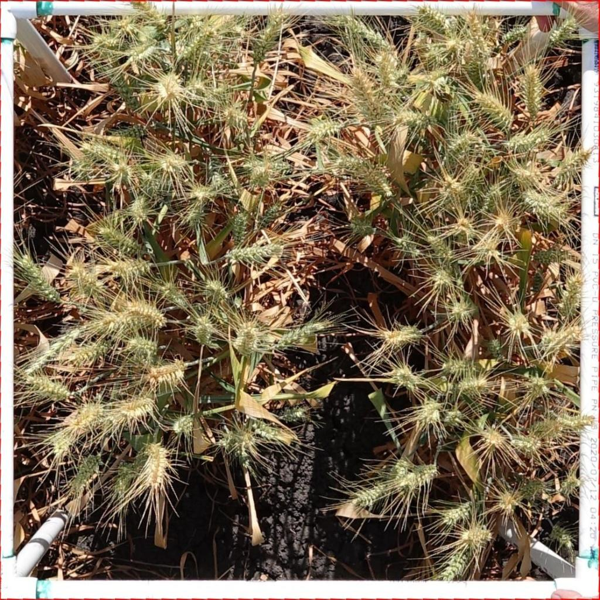

Image 512 x 512 593,758 bytes


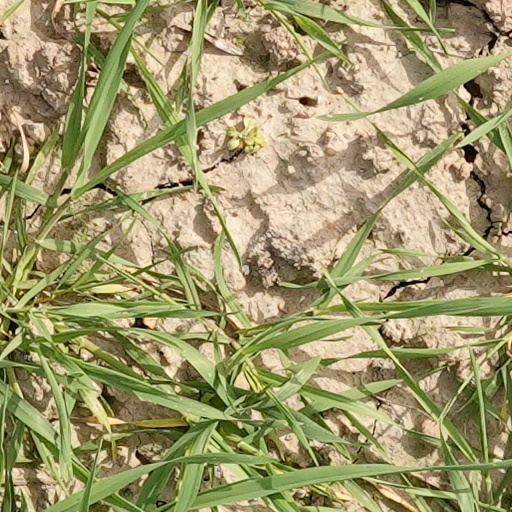

In [25]:
# Check image fetch and display

output = Path("images")
output.mkdir(exist_ok=True)

images = {
    "gwhd-00000000.jpg":
        "https://data.global-wheat.com/gwhd/images/00000000.jpg",
    "gwfss-00000000.png":
        "https://data.global-wheat.com/gwfss/images/00000000.png",   
}

for file, url in images.items():
    response = requests.get(url, timeout=5)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content))
    img.load()

    dest = output / file
    dest.write_bytes(response.content)

    print(f"Image {img.width} x {img.height}", f"{len(response.content):,} bytes")

    preview = img.copy()
    preview.thumbnail((600, 600))
    display(preview)

In [26]:
# Load model

import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation

MODEL = "GlobalWheat/GWFSS_Segformer_b4"
device = "cuda"

if device == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable.")

processor = AutoImageProcessor.from_pretrained(MODEL)
model = SegformerForSemanticSegmentation.from_pretrained(MODEL).to(device).eval()

print("Loaded:", MODEL, "on", next(model.parameters()).device)


Loading weights: 100%|██████████| 930/930 [00:00<00:00, 5282.43it/s]


Loaded: GlobalWheat/GWFSS_Segformer_b4 on cuda:0


In [27]:
# Run inference

image = Image.open(output / "gwhd-00000000.jpg").convert("RGB")

with torch.inference_mode():
    inputs = processor(images=image, return_tensors="pt").to(device)
    logits = model(**inputs).logits
    logits = F.interpolate(
        logits, size=(image.height, image.width), mode="bilinear", align_corners=False
    )
    mask = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)

print("Inference:", logits.device, mask.shape)


Inference: cuda:0 (1024, 1024)


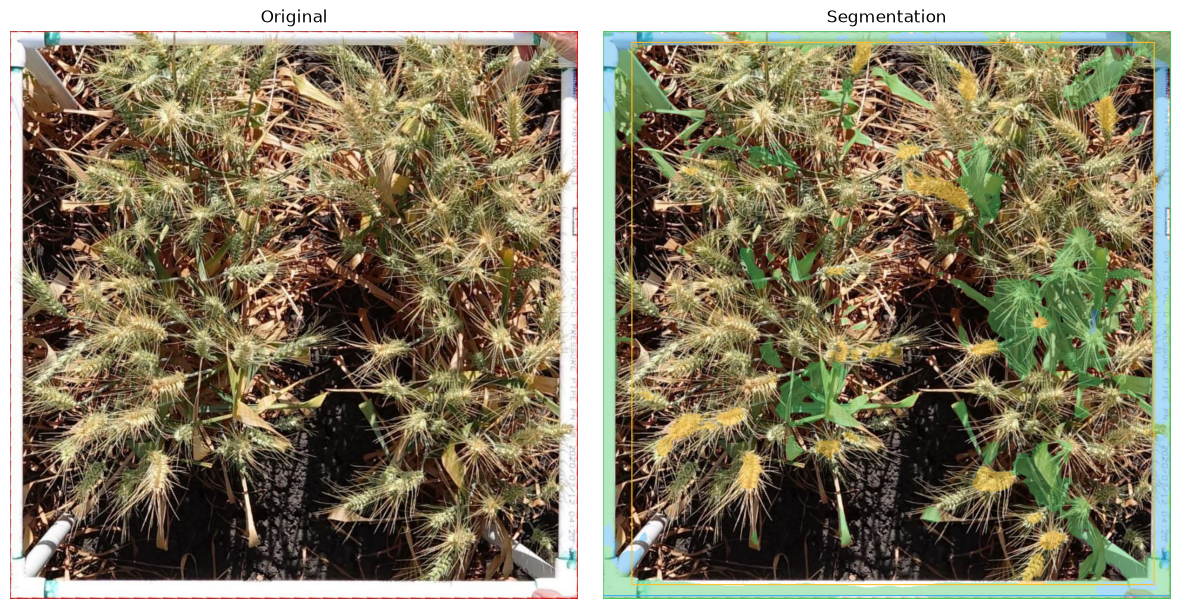

In [28]:
# Display masks and class boxes

import matplotlib.pyplot as plt
from PIL import ImageDraw

LABELS = ("background", "head", "stem", "leaf")
PALETTE = np.array([[0, 0, 0], [255, 190, 40], [50, 170, 240], [70, 200, 100]], dtype=np.uint8)

color_mask = Image.fromarray(PALETTE[mask])
overlay = Image.blend(image, color_mask, 0.4)
overlay = Image.composite(overlay, image, Image.fromarray((mask != 0).astype(np.uint8) * 255))
draw = ImageDraw.Draw(overlay)

for class_id, label in enumerate(LABELS):
    if class_id == 0:
        continue
    ys, xs = np.nonzero(mask == class_id)
    if not len(xs):
        continue
    box = (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
    color = tuple(PALETTE[class_id].tolist())
    draw.rectangle(box, outline=color, width=2)
    draw.text(box[:2], label, fill=color)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[1].imshow(overlay)
axes[1].set_title("Segmentation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
plt.close(fig)